<center><h1> ESNGrad <h1><center>

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import torch 
import pandas as pd 
import numpy as np

# 1. Forecasting the RV

We try a simple forecast of the RV as in the paper. 

In [3]:
filename = 'data/SP500_RV_5min.xlsx'
raw = pd.read_excel(filename)
raw['Date'] = pd.to_datetime(raw['Date'], format='%Y%m%d')
dates = raw['Date'].to_numpy()
RV = raw['RV']
print(RV.describe())
RV = torch.tensor(raw['RV'].to_numpy(), dtype=torch.float32).reshape(-1, 1)
len_train = 2000
RV_train = RV[:len_train].clone()
RV_test = RV[len_train:].clone()
dates_train = dates[:len_train]
dates_test = dates[len_train:]

count    4096.000000
mean        1.175221
std         2.315118
min         0.043289
25%         0.322543
50%         0.629452
75%         1.177538
max        60.562509
Name: RV, dtype: float64


## 1.1. Training

First we need to define our diffusion process. We use the standard `DDPM`. 

In [4]:
from rcdiff.diff import DDPM, BaseScheduler

K = 100

scheduler = BaseScheduler(K = K)
ddpm = DDPM(scheduler=scheduler)

Second, we need to define the encoder network. We use the `ESN` module and sample the parameters: 

In [5]:
from rcdiff import ESN 
from rcdiff import RandomWeight, ParametersESN

R = 25 
T, N = RV_train.shape

A = RandomWeight(dist="normal", sparsity=0, norm_type="spectral_radius")
C = RandomWeight(dist="uniform", sparsity=0, norm_type="l2")
zeta = RandomWeight(dist="uniform", sparsity=0, norm_type="euclidean")

esnParams = ParametersESN(A_RW = A, 
                 C_RW = C,
                 zeta_RW = zeta,
                 leak_rate = 0.3, 
                 rho = 0.9, 
                 gamma = 0.1,
                 omega = 0) 

esn = ESN(in_dim = N, 
          reservoir_size= R, 
          params=esnParams
          )

Then we need to define the denoiser network. Here we use the `SimpleMLP` network

In [ ]:
from rcdiff.models.denoisers import SimpleMLP 

denoiser = SimpleMLP(in_dim=N,cond_dim=R, dim_hids=[32,32], time_dim=132)

Here we then define the training characteristics of the network: 

In [ ]:
from rcdiff.models.config import TrainConfig

train_spec = TrainConfig(t0 = 100,                            
    batch_size = 256,
    lr = 1e-3,
    max_iters = 1000,
    val_fraction = 0.25, 
    eval_every = 1,
    patience = 100,  
    ema_decay = 1,  
    grad_clip = 1.0,
    seed = 1234,
    device = "cpu")

In [ ]:
from rcdiff.models import ESNGrad

esnGrad = ESNGrad(diff = ddpm, esn = esn, denoiser = denoiser, spec = train_spec)
loss, time = esnGrad.fit(x = RV_train, c = None)

Early stopping at iteration 650 | best val loss 0.1078


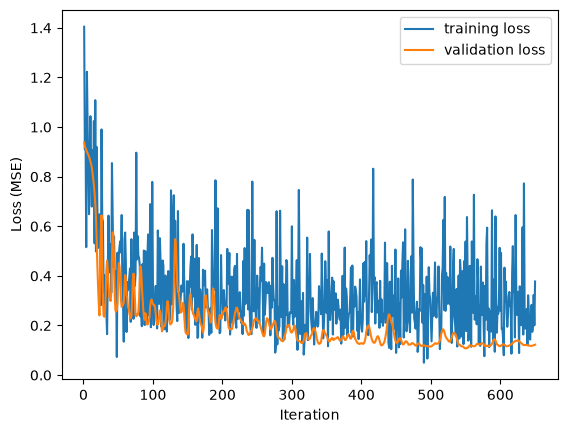

In [9]:
import matplotlib.pyplot as plt 

loss = pd.DataFrame(loss)
plt.plot(loss['iter'], loss['train'], label = 'training loss')
plt.plot(loss['iter'], loss['val'], label = 'validation loss')
plt.ylabel('Loss (MSE)')
plt.xlabel('Iteration')
plt.legend()
plt.show()

## 1.2. Test

Using the `conditional_distribution` method you can sample from $p(x_t|s_{t-1})$ 

In [10]:
x_hat, process_history = esnGrad.conditional_distribution(x = RV, c = None, n_samples=1000)

In [11]:
print(RV_test[0])
print(x_hat.mean(dim = 0))

tensor([0.6725])
tensor([0.5411])


using the `one_step_ahead_forecast` you perform a one-step ahead forecast in a recursive way

In [ ]:
obs = len(RV_test) # 1000 
test = RV_test[:obs]

forecast = esnGrad.one_step_ahead_forecast(x_train = RV_train, 
                                           x_test = test,
                                           n_samples = 50)

In [14]:
# torch.save(forecast, "forecast.pt")

forecast = torch.load("forecast.pt", weights_only=True)

In [15]:
import torch.nn.functional as F 

F_m = forecast.mean(dim = 1)

F.mse_loss(F_m, test) # should be around 3.6 to be good

tensor(3.7350)

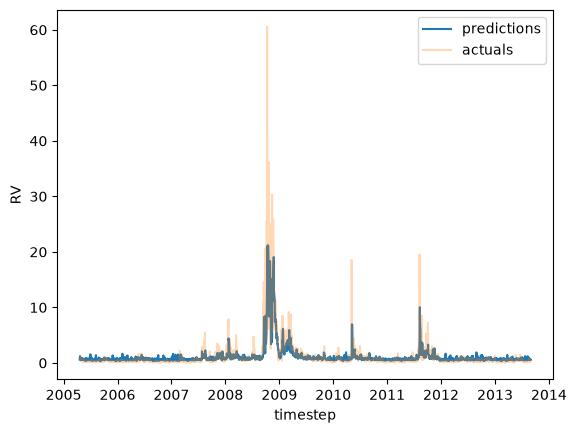

In [16]:
import matplotlib.pyplot as plt 

loss = pd.DataFrame(loss)
plt.plot(dates_test,F_m.detach().numpy(), label = 'predictions')
plt.plot(dates_test, RV_test.detach().numpy(), label = 'actuals', alpha = 0.3)
plt.ylabel('RV')
plt.xlabel('timestep')
plt.legend()
plt.show()

## Experiment: save configuration

In [ ]:
from rcdiff.models.config import (ExperimentConfig, build_diffusion, build_denoiser, ESNConfig, 
                                    DenoiserConfig, DiffusionConfig, build_esn)

cfg = ExperimentConfig(name="rv_log", in_dim=1,
                       esn=ESNConfig(reservoir_size=50, leak_rate=0.3, rho=0.95, gamma=0.2, omega=0.5),
                       denoiser=DenoiserConfig("simple_mlp", {"dim_hids": [32, 64, 32], "time_dim": 128}),
                       diffusion=DiffusionConfig(num_timesteps=100),
                       train=train_spec)

model = ESNGrad(diff=build_diffusion(cfg), esn=build_esn(cfg),
                denoiser=build_denoiser(cfg), spec=cfg.train)

history, secs = model.fit(RV_train, None)
model.save_checkpoint("runs/rv/best.pth", cfg, history=history)

model, cfg = ESNGrad.load_checkpoint("runs/rv_log/best.pth")

# FULL RC

In [ ]:
....

## 1.3. ESN with Linear Readout... 

In [17]:
N_train = 2000
X_train, y_train = RV[:(N_train-1)], RV[1:N_train]
X_test, y_test = RV[N_train:(len(RV)-1)], RV[(N_train+1):(len(RV)-1)]

In [18]:
x_all = RV_train
s = esn.get_states(x_all)                     # (T, R): s[j] = s_{j+1}
ones = lambda a: torch.cat([a, torch.ones(len(a), 1)], 1)
Xtr, ytr = ones(s[:1999]), x_all[1:2000]      # s_t -> x_{t+1}, training window only
lam = 1e-4
W = torch.linalg.solve(Xtr.T @ Xtr + lam * torch.eye(Xtr.shape[1]), Xtr.T @ ytr)
pred = ones(s[1999:-1]) @ W                   # forecasts of x[2000:], one step ahead

In [19]:
N_train = 2000
x_all = RV.float()                        # FULL series (T, 1), same transform as in training
s = esn.get_states(x_all)                 # (T, R); s[j] = s_{j+1}, uses only x_all[:j+1]

ones = lambda a: torch.cat([a, torch.ones(len(a), 1)], 1)
Xtr, ytr = ones(s[:N_train-1]), x_all[1:N_train]      # (s_t -> x_{t+1}), training window only
lam = 1e-4
W = torch.linalg.solve(Xtr.T @ Xtr + lam * torch.eye(Xtr.shape[1]), Xtr.T @ ytr)

pred   = ones(s[N_train-1:-1]) @ W        # forecasts of x_all[N_train:], one step ahead
y_test = x_all[N_train:]
print(pred.shape, y_test.shape)           # both (T - N_train, 1)
print("MSE:", ((pred - y_test) ** 2).mean().item())

torch.Size([2096, 1]) torch.Size([2096, 1])
MSE: 5.334643840789795


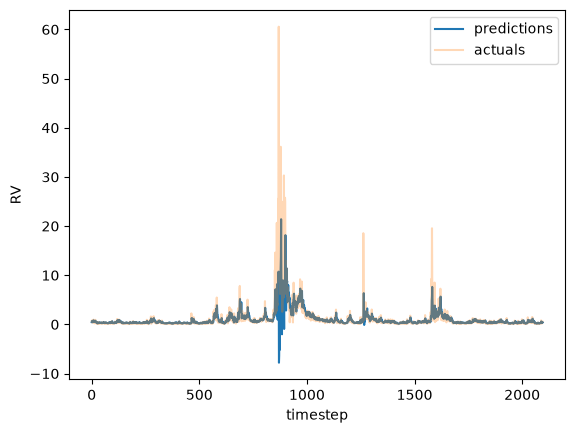

In [20]:
import matplotlib.pyplot as plt 

plt.plot(pred.detach().numpy(), label = 'predictions')
plt.plot(RV_test.detach().numpy(), label = 'actuals', alpha = 0.3)
plt.ylabel('RV')
plt.xlabel('timestep')
plt.legend()
plt.show()

# 2. Multivariate example with VAR

A second example to test the model on a multivariate process

In [ ]:
from rcdiff.data.var import VAR

Phi_1 = np.array([[0.5,0.1,0], [0,.1,.2],[0,.3,.3]]).T
Phi_2 = np.array([[0.25,0.06,0.02], [0,.07,8e-2],[0,.12,.15]]).T
Phi_3 = np.array([[0.125,0.037,0.018], [0,.031,.038],[0,.057,.069]]).T
sigma_u = np.array([[1.0, 0.3, 0.1],
                    [0.3, 1.0, 0.2],
                    [0.1, 0.2, 1.0]])
A = [Phi_1, Phi_2, Phi_3]

var = VAR(A_coefs=A, sigma_u=sigma_u)
y = var.generate_trajectory(T = 1000, batch_size=1, burn_in=50)
y = y.squeeze(0)
print(y.shape) 
print(y)

torch.Size([1000, 3])
tensor([[ 0.4367, -0.2716,  0.4833],
        [-0.5561, -1.2001, -0.0352],
        [ 0.4464, -1.2994, -0.8928],
        ...,
        [-2.3647,  0.2285,  1.6384],
        [-1.7534,  1.5079,  1.0832],
        [-1.7216,  0.1179,  0.9037]])


In [ ]:
from rcdiff import ESN 
from rcdiff import RandomWeight, ParametersESN

R = 50 
T, N = y.shape
A = RandomWeight(dist="normal", sparsity=0.2,norm_type="spectral_radius")
C = RandomWeight(dist="uniform", sparsity=0.2,norm_type="l2")
zeta = RandomWeight(dist="uniform", sparsity=0.2,norm_type="euclidean")

esnParams = ParametersESN(A_RW = A, 
                 C_RW = C,
                 zeta_RW = zeta,
                 leak_rate = 0.2, 
                 rho = 0.1, 
                 gamma = 0.4,
                 omega = 0) 

esn = ESN(in_dim = N, 
          reservoir_size= R, 
          params=esnParams
          )

....